In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass


def lorentzian(x, x0, gamma):
    return gamma**2 / ((x - x0)**2 + gamma**2)

def normalize(v):
    n = np.linalg.norm(v)
    return v / n if n > 0 else v

k_B_cm = 0.69503476  # cm^-1 / K



@dataclass
class AggregateGeometry:
    positions: np.ndarray   # (N, 3)
    dipoles: np.ndarray     # (N, 3)

@dataclass
class DisorderAveragedResult:
    w_grid: np.ndarray
    abs_avg: np.ndarray
    em_avg: np.ndarray
    pop_avg: np.ndarray
    energy_samples: list
    osc_samples: list
    pop_samples: list

@dataclass
class PlasmonicResonator:
    omega_p_cm: float
    gamma_p_cm: float
    base_g_cm: float



def build_linear_chain(N=20, spacing=1.0, dipole_angle_deg=20.0):
    positions = np.zeros((N, 3), dtype=float)
    dipoles = np.zeros((N, 3), dtype=float)
    theta = np.deg2rad(dipole_angle_deg)

    mu = normalize(np.array([np.cos(theta), 0.0, np.sin(theta)]))
    for i in range(N):
        positions[i] = [i * spacing, 0.0, 0.0]
        dipoles[i] = mu
    return AggregateGeometry(positions, dipoles)


def build_ring(N=20, radius=4.0, tangential=True, tilt_deg=20.0):
    positions = np.zeros((N, 3), dtype=float)
    dipoles = np.zeros((N, 3), dtype=float)
    tilt = np.deg2rad(tilt_deg)

    for n in range(N):
        phi = 2 * np.pi * n / N
        positions[n] = [radius * np.cos(phi), radius * np.sin(phi), 0.0]

        radial = np.array([np.cos(phi), np.sin(phi), 0.0])
        tangent = np.array([-np.sin(phi), np.cos(phi), 0.0])

        in_plane = tangent if tangential else radial
        mu = np.cos(tilt) * in_plane + np.sin(tilt) * np.array([0.0, 0.0, 1.0])
        dipoles[n] = normalize(mu)

    return AggregateGeometry(positions, dipoles)


def build_elliptic_ring(N=20, a=5.0, b=3.0, tangential=True, tilt_deg=20.0):
    positions = np.zeros((N, 3), dtype=float)
    dipoles = np.zeros((N, 3), dtype=float)
    tilt = np.deg2rad(tilt_deg)

    for n in range(N):
        phi = 2 * np.pi * n / N
        x = a * np.cos(phi)
        y = b * np.sin(phi)
        positions[n] = [x, y, 0.0]

        radial = normalize(np.array([x / max(a, 1e-12), y / max(b, 1e-12), 0.0]))
        tangent_vec = np.array([-a * np.sin(phi), b * np.cos(phi), 0.0])
        tangent = normalize(tangent_vec)

        in_plane = tangent if tangential else radial
        mu = np.cos(tilt) * in_plane + np.sin(tilt) * np.array([0.0, 0.0, 1.0])
        dipoles[n] = normalize(mu)

    return AggregateGeometry(positions, dipoles)


def build_cylinder(
    n_rings=8,
    molecules_per_ring=8,
    radius=3.5,
    pitch=1.1,
    helical_twist_deg=18.0,
    dipole_tilt_deg=20.0,
    dipole_azimuthal=True
):
    N = n_rings * molecules_per_ring
    positions = np.zeros((N, 3), dtype=float)
    dipoles = np.zeros((N, 3), dtype=float)

    twist = np.deg2rad(helical_twist_deg)
    tilt = np.deg2rad(dipole_tilt_deg)

    idx = 0
    for m in range(n_rings):
        z = m * pitch
        ring_shift = m * twist
        for n in range(molecules_per_ring):
            phi = 2 * np.pi * n / molecules_per_ring + ring_shift
            positions[idx] = [radius * np.cos(phi), radius * np.sin(phi), z]

            radial = np.array([np.cos(phi), np.sin(phi), 0.0])
            tangent = np.array([-np.sin(phi), np.cos(phi), 0.0])
            in_plane = tangent if dipole_azimuthal else radial
            mu = np.cos(tilt) * in_plane + np.sin(tilt) * np.array([0.0, 0.0, 1.0])
            dipoles[idx] = normalize(mu)
            idx += 1

    return AggregateGeometry(positions, dipoles)


def build_double_wall_tube(
    n_rings=8,
    molecules_per_ring_inner=8,
    molecules_per_ring_outer=10,
    radius_inner=3.0,
    radius_outer=4.0,
    pitch=1.1,
    helical_twist_deg=18.0,
    wall_offset_deg=10.0,
    dipole_tilt_deg=20.0,
    dipole_azimuthal=True
):
    inner = build_cylinder(
        n_rings=n_rings,
        molecules_per_ring=molecules_per_ring_inner,
        radius=radius_inner,
        pitch=pitch,
        helical_twist_deg=helical_twist_deg,
        dipole_tilt_deg=dipole_tilt_deg,
        dipole_azimuthal=dipole_azimuthal
    )

    outer_twist = helical_twist_deg + wall_offset_deg
    outer = build_cylinder(
        n_rings=n_rings,
        molecules_per_ring=molecules_per_ring_outer,
        radius=radius_outer,
        pitch=pitch,
        helical_twist_deg=outer_twist,
        dipole_tilt_deg=dipole_tilt_deg,
        dipole_azimuthal=dipole_azimuthal
    )

    positions = np.vstack([inner.positions, outer.positions])
    dipoles = np.vstack([inner.dipoles, outer.dipoles])
    return AggregateGeometry(positions, dipoles)


def build_elliptic_tube(
    n_rings=8,
    molecules_per_ring=10,
    a=5.0,
    b=3.0,
    pitch=1.1,
    helical_twist_deg=18.0,
    dipole_tilt_deg=20.0,
    dipole_azimuthal=True
):
    N = n_rings * molecules_per_ring
    positions = np.zeros((N, 3), dtype=float)
    dipoles = np.zeros((N, 3), dtype=float)

    twist = np.deg2rad(helical_twist_deg)
    tilt = np.deg2rad(dipole_tilt_deg)

    idx = 0
    for m in range(n_rings):
        z = m * pitch
        shift = m * twist
        for n in range(molecules_per_ring):
            phi = 2 * np.pi * n / molecules_per_ring + shift
            x = a * np.cos(phi)
            y = b * np.sin(phi)
            positions[idx] = [x, y, z]

            radial = normalize(np.array([x / max(a, 1e-12), y / max(b, 1e-12), 0.0]))
            tangent = normalize(np.array([-a * np.sin(phi), b * np.cos(phi), 0.0]))
            in_plane = tangent if dipole_azimuthal else radial
            mu = np.cos(tilt) * in_plane + np.sin(tilt) * np.array([0.0, 0.0, 1.0])
            dipoles[idx] = normalize(mu)
            idx += 1

    return AggregateGeometry(positions, dipoles)


def build_helix(
    N=40,
    radius=3.0,
    pitch_per_turn=5.0,
    n_turns=4.0,
    dipole_tilt_deg=20.0,
    dipole_follow_tangent=True
):
    positions = np.zeros((N, 3), dtype=float)
    dipoles = np.zeros((N, 3), dtype=float)
    tilt = np.deg2rad(dipole_tilt_deg)

    for i in range(N):
        t = 2 * np.pi * n_turns * i / max(N - 1, 1)
        x = radius * np.cos(t)
        y = radius * np.sin(t)
        z = pitch_per_turn * t / (2 * np.pi)
        positions[i] = [x, y, z]

        tangent = normalize(np.array([
            -radius * np.sin(t),
            radius * np.cos(t),
            pitch_per_turn / (2 * np.pi)
        ]))
        radial = normalize(np.array([np.cos(t), np.sin(t), 0.0]))

        base = tangent if dipole_follow_tangent else radial
        mu = np.cos(tilt) * base + np.sin(tilt) * np.array([0.0, 0.0, 1.0])
        dipoles[i] = normalize(mu)

    return AggregateGeometry(positions, dipoles)


def build_ribbon_2d(
    n_x=10,
    n_y=4,
    spacing_x=1.0,
    spacing_y=1.2,
    dipole_angle_deg=20.0
):
    N = n_x * n_y
    positions = np.zeros((N, 3), dtype=float)
    dipoles = np.zeros((N, 3), dtype=float)

    theta = np.deg2rad(dipole_angle_deg)
    mu = normalize(np.array([np.cos(theta), 0.0, np.sin(theta)]))

    idx = 0
    for iy in range(n_y):
        for ix in range(n_x):
            positions[idx] = [ix * spacing_x, iy * spacing_y, 0.0]
            dipoles[idx] = mu
            idx += 1

    return AggregateGeometry(positions, dipoles)


def build_brick_layer_sheet(
    n_x=10,
    n_y=4,
    spacing_x=1.0,
    spacing_y=1.2,
    slip_x=0.5,
    dipole_angle_deg=20.0
):
    N = n_x * n_y
    positions = np.zeros((N, 3), dtype=float)
    dipoles = np.zeros((N, 3), dtype=float)

    theta = np.deg2rad(dipole_angle_deg)
    mu = normalize(np.array([np.cos(theta), 0.0, np.sin(theta)]))

    idx = 0
    for iy in range(n_y):
        shift = slip_x if (iy % 2 == 1) else 0.0
        for ix in range(n_x):
            positions[idx] = [ix * spacing_x + shift, iy * spacing_y, 0.0]
            dipoles[idx] = mu
            idx += 1

    return AggregateGeometry(positions, dipoles)


def build_stacked_rings(
    n_rings=6,
    molecules_per_ring=12,
    radius=4.0,
    ring_spacing=1.0,
    ring_rotation_deg=10.0,
    tangential=True,
    tilt_deg=20.0
):
    all_pos = []
    all_mu = []
    rot = np.deg2rad(ring_rotation_deg)

    for m in range(n_rings):
        base = build_ring(
            N=molecules_per_ring,
            radius=radius,
            tangential=tangential,
            tilt_deg=tilt_deg
        )
        angle = m * rot
        R = np.array([
            [np.cos(angle), -np.sin(angle), 0.0],
            [np.sin(angle),  np.cos(angle), 0.0],
            [0.0,            0.0,           1.0]
        ])

        pos = base.positions @ R.T
        mu = base.dipoles @ R.T
        pos[:, 2] += m * ring_spacing

        all_pos.append(pos)
        all_mu.append(mu)

    return AggregateGeometry(np.vstack(all_pos), np.vstack(all_mu))


def build_tube_radial_disorder(
    n_rings=8,
    molecules_per_ring=8,
    radius=3.5,
    radial_sigma=0.2,
    pitch=1.1,
    helical_twist_deg=18.0,
    dipole_tilt_deg=20.0,
    dipole_azimuthal=True,
    seed=0
):
    rng = np.random.default_rng(seed)
    N = n_rings * molecules_per_ring
    positions = np.zeros((N, 3), dtype=float)
    dipoles = np.zeros((N, 3), dtype=float)

    twist = np.deg2rad(helical_twist_deg)
    tilt = np.deg2rad(dipole_tilt_deg)

    idx = 0
    for m in range(n_rings):
        z = m * pitch
        shift = m * twist
        for n in range(molecules_per_ring):
            phi = 2 * np.pi * n / molecules_per_ring + shift
            r_local = radius + rng.normal(0.0, radial_sigma)

            positions[idx] = [r_local * np.cos(phi), r_local * np.sin(phi), z]

            radial = np.array([np.cos(phi), np.sin(phi), 0.0])
            tangent = np.array([-np.sin(phi), np.cos(phi), 0.0])
            in_plane = tangent if dipole_azimuthal else radial
            mu = np.cos(tilt) * in_plane + np.sin(tilt) * np.array([0.0, 0.0, 1.0])
            dipoles[idx] = normalize(mu)
            idx += 1

    return AggregateGeometry(positions, dipoles)


def build_tube_variable_pitch(
    n_rings=8,
    molecules_per_ring=8,
    radius=3.5,
    pitch0=0.9,
    pitch1=1.4,
    helical_twist_deg=18.0,
    dipole_tilt_deg=20.0,
    dipole_azimuthal=True
):
    N = n_rings * molecules_per_ring
    positions = np.zeros((N, 3), dtype=float)
    dipoles = np.zeros((N, 3), dtype=float)

    twist = np.deg2rad(helical_twist_deg)
    tilt = np.deg2rad(dipole_tilt_deg)

    ring_z = np.zeros(n_rings)
    pitches = np.linspace(pitch0, pitch1, max(n_rings - 1, 1))
    for m in range(1, n_rings):
        ring_z[m] = ring_z[m - 1] + pitches[m - 1]

    idx = 0
    for m in range(n_rings):
        z = ring_z[m]
        shift = m * twist
        for n in range(molecules_per_ring):
            phi = 2 * np.pi * n / molecules_per_ring + shift
            positions[idx] = [radius * np.cos(phi), radius * np.sin(phi), z]

            radial = np.array([np.cos(phi), np.sin(phi), 0.0])
            tangent = np.array([-np.sin(phi), np.cos(phi), 0.0])
            in_plane = tangent if dipole_azimuthal else radial
            mu = np.cos(tilt) * in_plane + np.sin(tilt) * np.array([0.0, 0.0, 1.0])
            dipoles[idx] = normalize(mu)
            idx += 1

    return AggregateGeometry(positions, dipoles)


def build_tapered_tube(
    n_rings=8,
    molecules_per_ring=8,
    radius0=3.0,
    radius1=5.0,
    pitch=1.1,
    helical_twist_deg=18.0,
    dipole_tilt_deg=20.0,
    dipole_azimuthal=True
):
    N = n_rings * molecules_per_ring
    positions = np.zeros((N, 3), dtype=float)
    dipoles = np.zeros((N, 3), dtype=float)

    twist = np.deg2rad(helical_twist_deg)
    tilt = np.deg2rad(dipole_tilt_deg)
    radii = np.linspace(radius0, radius1, n_rings)

    idx = 0
    for m in range(n_rings):
        z = m * pitch
        r = radii[m]
        shift = m * twist
        for n in range(molecules_per_ring):
            phi = 2 * np.pi * n / molecules_per_ring + shift
            positions[idx] = [r * np.cos(phi), r * np.sin(phi), z]

            radial = np.array([np.cos(phi), np.sin(phi), 0.0])
            tangent = np.array([-np.sin(phi), np.cos(phi), 0.0])
            in_plane = tangent if dipole_azimuthal else radial
            mu = np.cos(tilt) * in_plane + np.sin(tilt) * np.array([0.0, 0.0, 1.0])
            dipoles[idx] = normalize(mu)
            idx += 1

    return AggregateGeometry(positions, dipoles)



def build_geometry(config):
    gtype = config["geometry_type"]
    params = config.get("geometry_params", {})

    if gtype == "linear_chain":
        return build_linear_chain(**params)
    elif gtype == "ring":
        return build_ring(**params)
    elif gtype == "elliptic_ring":
        return build_elliptic_ring(**params)
    elif gtype == "cylinder":
        return build_cylinder(**params)
    elif gtype == "double_wall_tube":
        return build_double_wall_tube(**params)
    elif gtype == "elliptic_tube":
        return build_elliptic_tube(**params)
    elif gtype == "helix":
        return build_helix(**params)
    elif gtype == "ribbon_2d":
        return build_ribbon_2d(**params)
    elif gtype == "brick_layer_sheet":
        return build_brick_layer_sheet(**params)
    elif gtype == "stacked_rings":
        return build_stacked_rings(**params)
    elif gtype == "tube_radial_disorder":
        return build_tube_radial_disorder(**params)
    elif gtype == "tube_variable_pitch":
        return build_tube_variable_pitch(**params)
    elif gtype == "tapered_tube":
        return build_tapered_tube(**params)
    else:
        raise ValueError(f"Unknown geometry type: {gtype}")



def dipole_dipole_coupling(rij, mui, muj, J0=1000.0, r0=1.0):
    r = np.linalg.norm(rij)
    if r < 1e-12:
        return 0.0
    rhat = rij / r
    orient = np.dot(mui, muj) - 3.0 * np.dot(mui, rhat) * np.dot(muj, rhat)
    return J0 * (r0 / r)**3 * orient

def build_frenkel_hamiltonian(
    geometry,
    monomer_energy_cm=17000.0,
    J0=900.0,
    disorder_sigma_cm=60.0,
    seed=None
):
    rng = np.random.default_rng(seed)
    N = len(geometry.positions)
    H = np.zeros((N, N), dtype=float)

    site_energies = monomer_energy_cm + rng.normal(0.0, disorder_sigma_cm, size=N)
    np.fill_diagonal(H, site_energies)

    for i in range(N):
        for j in range(i + 1, N):
            rij = geometry.positions[j] - geometry.positions[i]
            Jij = dipole_dipole_coupling(rij, geometry.dipoles[i], geometry.dipoles[j], J0=J0)
            H[i, j] = Jij
            H[j, i] = Jij
    return H

def diagonalize_exciton_hamiltonian(H, dipoles):
    energies, vecs = np.linalg.eigh(H)
    bright_dipoles = vecs.T @ dipoles
    oscillator_strengths = np.sum(bright_dipoles**2, axis=1)
    return energies, vecs, bright_dipoles, oscillator_strengths



def absorption_spectrum(energies, osc, w_grid, gamma_cm=80.0):
    spec = np.zeros_like(w_grid, dtype=float)
    for E, f in zip(energies, osc):
        spec += f * lorentzian(w_grid, E, gamma_cm)
    return spec

def bose_factor(delta_cm, T):
    if delta_cm <= 0:
        return 0.0
    x = delta_cm / (k_B_cm * T)
    if x > 700:
        return 0.0
    return 1.0 / (np.exp(x) - 1.0)

def build_exciton_transition_rates(
    energies,
    eigenvectors,
    T=300.0,
    W0=1.0,
    spectral_cutoff_cm=300.0,
    use_overlap=True
):
    N = len(energies)
    K = np.zeros((N, N), dtype=float)

    prob = eigenvectors**2
    overlap_matrix = prob.T @ prob if use_overlap else np.ones((N, N))

    for n in range(N):
        for m in range(N):
            if m == n:
                continue
            delta = abs(energies[n] - energies[m])
            Jbath = (delta / spectral_cutoff_cm) * np.exp(-delta / spectral_cutoff_cm)
            overlap = overlap_matrix[m, n]

            if energies[n] > energies[m]:
                rate = W0 * overlap * Jbath * (bose_factor(delta, T) + 1.0)
            else:
                rate = W0 * overlap * Jbath * bose_factor(delta, T)
            K[m, n] = rate

    for n in range(N):
        K[n, n] = -np.sum(K[:, n])
    return K

def apply_decay_channels(K, osc, gamma_rad_base=0.02, gamma_nr=0.002):
    K2 = K.copy()
    for n in range(len(osc)):
        loss = gamma_rad_base * osc[n] + gamma_nr
        K2[n, n] -= loss
    return K2

def build_pump_vector_from_absorption(osc):
    p = np.array(osc, dtype=float)
    if p.sum() <= 0:
        return np.ones_like(p) / len(p)
    return p / p.sum()

def solve_stationary_populations(K, pump=None):
    N = K.shape[0]
    if pump is None:
        pump = np.ones(N) / N
    else:
        pump = np.asarray(pump, dtype=float)

    A = K.copy()
    b = -pump.copy()

    A[-1, :] = 1.0
    b[-1] = 1.0

    P = np.linalg.solve(A, b)
    P = np.maximum(P, 0.0)
    if P.sum() > 0:
        P /= P.sum()
    return P

def fluorescence_spectrum_from_populations(
    energies,
    osc,
    populations,
    w_grid,
    gamma_cm=90.0,
    stokes_shift_cm=120.0
):
    spec = np.zeros_like(w_grid, dtype=float)
    for E, f, p in zip(energies, osc, populations):
        spec += p * f * lorentzian(w_grid, E - stokes_shift_cm, gamma_cm)
    return spec



def run_disorder_ensemble(
    geometry,
    n_realizations=30,
    monomer_energy_cm=17000.0,
    J0=900.0,
    disorder_sigma_cm=60.0,
    T=300.0,
    W0=1.0,
    spectral_cutoff_cm=300.0,
    gamma_abs_cm=80.0,
    gamma_em_cm=90.0,
    stokes_shift_cm=120.0,
    gamma_rad_base=0.02,
    gamma_nr=0.002,
    wmin=15500.0,
    wmax=18000.0,
    nw=2000,
    seed=1234
):
    rng = np.random.default_rng(seed)
    w = np.linspace(wmin, wmax, nw)

    abs_acc = np.zeros_like(w)
    em_acc = np.zeros_like(w)

    energy_samples = []
    osc_samples = []
    pop_samples = []

    for _ in range(n_realizations):
        H = build_frenkel_hamiltonian(
            geometry=geometry,
            monomer_energy_cm=monomer_energy_cm,
            J0=J0,
            disorder_sigma_cm=disorder_sigma_cm,
            seed=int(rng.integers(0, 10**9))
        )

        energies, vecs, bright_dipoles, osc = diagonalize_exciton_hamiltonian(H, geometry.dipoles)
        abs_spec = absorption_spectrum(energies, osc, w, gamma_cm=gamma_abs_cm)

        K = build_exciton_transition_rates(
            energies=energies,
            eigenvectors=vecs,
            T=T,
            W0=W0,
            spectral_cutoff_cm=spectral_cutoff_cm,
            use_overlap=True
        )
        K_decay = apply_decay_channels(K, osc, gamma_rad_base=gamma_rad_base, gamma_nr=gamma_nr)
        pump = build_pump_vector_from_absorption(osc)
        pops = solve_stationary_populations(K_decay, pump=pump)

        em_spec = fluorescence_spectrum_from_populations(
            energies, osc, pops, w,
            gamma_cm=gamma_em_cm,
            stokes_shift_cm=stokes_shift_cm
        )

        abs_acc += abs_spec
        em_acc += em_spec
        energy_samples.append(energies)
        osc_samples.append(osc)
        pop_samples.append(pops)

    abs_avg = abs_acc / n_realizations
    em_avg = em_acc / n_realizations
    pop_avg = np.mean(np.array(pop_samples), axis=0)

    return DisorderAveragedResult(
        w_grid=w,
        abs_avg=abs_avg,
        em_avg=em_avg,
        pop_avg=pop_avg,
        energy_samples=energy_samples,
        osc_samples=osc_samples,
        pop_samples=pop_samples
    )



def resonator_from_shape(shape, size_nm=30.0, aspect_ratio=1.0):
    shape = shape.lower()

    if shape == "sphere":
        omega_p = 17500.0
        gamma_p = 250.0
        g0 = 120.0
    elif shape == "rod":
        omega_p = 17500.0 - 1800.0 * (aspect_ratio - 1.0)
        gamma_p = 220.0
        g0 = 160.0 * np.sqrt(aspect_ratio)
    elif shape == "disk":
        omega_p = 16800.0 + 400.0 / max(aspect_ratio, 0.3)
        gamma_p = 280.0
        g0 = 140.0
    else:
        raise ValueError("shape must be 'sphere', 'rod', or 'disk'")

    return PlasmonicResonator(omega_p_cm=omega_p, gamma_p_cm=gamma_p, base_g_cm=g0)

def geometry_overlap_factor(
    geometry,
    field_axis=np.array([1.0, 0.0, 0.0]),
    hotspot=np.array([0.0, 0.0, 0.0])
):
    field_axis = normalize(field_axis)
    weights = []
    for r, mu in zip(geometry.positions, geometry.dipoles):
        dist = np.linalg.norm(r - hotspot)
        orient = abs(np.dot(mu, field_axis))
        near_field = 1.0 / (dist + 1.0)**3
        weights.append(orient * near_field)
    weights = np.array(weights)
    return np.mean(weights) / (np.max(weights) + 1e-12)

def build_plexciton_hamiltonian(
    exciton_energies,
    exciton_bright_dipoles,
    geometry,
    resonator,
    n_bright=6,
    field_axis=np.array([1.0, 0.0, 0.0]),
    hotspot=np.array([0.0, 0.0, 0.0])
):
    osc = np.sum(exciton_bright_dipoles**2, axis=1)
    bright_idx = np.argsort(osc)[::-1][:min(n_bright, len(osc))]
    overlap = geometry_overlap_factor(geometry, field_axis=field_axis, hotspot=hotspot)

    E = exciton_energies[bright_idx]
    M = exciton_bright_dipoles[bright_idx]
    g = resonator.base_g_cm * overlap * np.sqrt(np.sum(M**2, axis=1) + 1e-12)

    dim = 1 + len(bright_idx)
    H = np.zeros((dim, dim), dtype=float)
    H[0, 0] = resonator.omega_p_cm
    H[1:, 1:] = np.diag(E)
    H[0, 1:] = g
    H[1:, 0] = g

    eigvals, eigvecs = np.linalg.eigh(H)
    return H, eigvals, eigvecs, bright_idx, g

def plexciton_spectrum(
    eigvals,
    eigvecs,
    resonator,
    exciton_bright_dipoles,
    bright_idx,
    w_grid,
    gamma_x_cm=90.0
):
    spec = np.zeros_like(w_grid, dtype=float)
    exc_osc = np.sum(exciton_bright_dipoles[bright_idx]**2, axis=1)

    for n in range(len(eigvals)):
        plasmon_weight = eigvecs[0, n]**2
        exciton_weights = eigvecs[1:, n]**2
        hybrid_strength = plasmon_weight + np.sum(exciton_weights * exc_osc)
        gamma_eff = plasmon_weight * resonator.gamma_p_cm + np.sum(exciton_weights) * gamma_x_cm
        spec += hybrid_strength * lorentzian(w_grid, eigvals[n], gamma_eff)

    return spec



def simulate_configuration(
    config,
    exciton_params,
    disorder_params,
    plasmon_shape="sphere",
    plasmon_params=None
):
    geom = build_geometry(config)

    ensemble_result = run_disorder_ensemble(
        geometry=geom,
        **exciton_params,
        **disorder_params
    )

    rep_seed = config.get("representative_seed", 123)
    H = build_frenkel_hamiltonian(
        geometry=geom,
        monomer_energy_cm=exciton_params["monomer_energy_cm"],
        J0=exciton_params["J0"],
        disorder_sigma_cm=exciton_params["disorder_sigma_cm"],
        seed=rep_seed
    )
    energies, vecs, bright_dipoles, osc = diagonalize_exciton_hamiltonian(H, geom.dipoles)

    if plasmon_params is None:
        resonator = resonator_from_shape(plasmon_shape)
    else:
        resonator = resonator_from_shape(plasmon_shape, **plasmon_params)

    Hpx, Epx, Vpx, bright_idx, g = build_plexciton_hamiltonian(
        exciton_energies=energies,
        exciton_bright_dipoles=bright_dipoles,
        geometry=geom,
        resonator=resonator,
        n_bright=config.get("n_bright_for_plexciton", 6),
        field_axis=np.array(config.get("field_axis", [1.0, 0.0, 0.0])),
        hotspot=np.array(config.get("hotspot", [0.0, 0.0, 0.0]))
    )

    plex_spec = plexciton_spectrum(
        Epx, Vpx, resonator,
        bright_dipoles, bright_idx,
        ensemble_result.w_grid
    )

    return {
        "name": config["name"],
        "geometry_type": config["geometry_type"],
        "geometry": geom,
        "w_grid": ensemble_result.w_grid,
        "absorption": ensemble_result.abs_avg,
        "fluorescence": ensemble_result.em_avg,
        "plexciton": plex_spec,
        "exciton_energies": energies,
        "oscillator_strengths": osc,
        "plexciton_energies": Epx,
        "couplings_g": g
    }

def simulate_configurations(
    configs,
    exciton_params,
    disorder_params,
    plasmon_shape="sphere",
    plasmon_params=None
):
    results = []
    for cfg in configs:
        res = simulate_configuration(
            config=cfg,
            exciton_params=exciton_params,
            disorder_params=disorder_params,
            plasmon_shape=plasmon_shape,
            plasmon_params=plasmon_params
        )
        results.append(res)
    return results



def _norm(y):
    ymax = np.max(y)
    return y / ymax if ymax > 0 else y

def plot_all_absorption(results):
    plt.figure(figsize=(10, 5))
    for res in results:
        plt.plot(res["w_grid"], _norm(res["absorption"]), label=res["name"])
    plt.xlabel("Wavenumber, cm$^{-1}$")
    plt.ylabel("Normalized absorption")
    plt.title("Absorption for multiple configurations")
    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_all_fluorescence(results):
    plt.figure(figsize=(10, 5))
    for res in results:
        plt.plot(res["w_grid"], _norm(res["fluorescence"]), label=res["name"])
    plt.xlabel("Wavenumber, cm$^{-1}$")
    plt.ylabel("Normalized fluorescence")
    plt.title("Fluorescence for multiple configurations")
    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_all_plexciton(results):
    plt.figure(figsize=(10, 5))
    for res in results:
        plt.plot(res["w_grid"], _norm(res["plexciton"]), label=res["name"])
    plt.xlabel("Wavenumber, cm$^{-1}$")
    plt.ylabel("Normalized hybrid intensity")
    plt.title("Plasmon-exciton spectra for multiple configurations")
    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_per_configuration(results):
    for res in results:
        fig = plt.figure(figsize=(10, 12))

        ax1 = fig.add_subplot(3, 1, 1)
        ax1.plot(res["w_grid"], _norm(res["absorption"]))
        ax1.set_title(f'{res["name"]}: Absorption')
        ax1.set_xlabel("Wavenumber, cm$^{-1}$")
        ax1.set_ylabel("Norm. intensity")

        ax2 = fig.add_subplot(3, 1, 2)
        ax2.plot(res["w_grid"], _norm(res["fluorescence"]))
        ax2.set_title(f'{res["name"]}: Fluorescence')
        ax2.set_xlabel("Wavenumber, cm$^{-1}$")
        ax2.set_ylabel("Norm. intensity")

        ax3 = fig.add_subplot(3, 1, 3)
        ax3.plot(res["w_grid"], _norm(res["plexciton"]))
        ax3.set_title(f'{res["name"]}: Plasmon-exciton')
        ax3.set_xlabel("Wavenumber, cm$^{-1}$")
        ax3.set_ylabel("Norm. intensity")

        plt.tight_layout()
        plt.show()

def plot_grouped_panels(results):
    """
    One figure with 3 panels:
    absorption / fluorescence / plexciton
    """
    fig = plt.figure(figsize=(12, 12))

    ax1 = fig.add_subplot(3, 1, 1)
    for res in results:
        ax1.plot(res["w_grid"], _norm(res["absorption"]), label=res["name"])
    ax1.set_title("Absorption")
    ax1.set_xlabel("Wavenumber, cm$^{-1}$")
    ax1.set_ylabel("Norm. intensity")
    ax1.legend()

    ax2 = fig.add_subplot(3, 1, 2)
    for res in results:
        ax2.plot(res["w_grid"], _norm(res["fluorescence"]), label=res["name"])
    ax2.set_title("Fluorescence")
    ax2.set_xlabel("Wavenumber, cm$^{-1}$")
    ax2.set_ylabel("Norm. intensity")
    ax2.legend()

    ax3 = fig.add_subplot(3, 1, 3)
    for res in results:
        ax3.plot(res["w_grid"], _norm(res["plexciton"]), label=res["name"])
    ax3.set_title("Plasmon-exciton")
    ax3.set_xlabel("Wavenumber, cm$^{-1}$")
    ax3.set_ylabel("Norm. intensity")
    ax3.legend()

    plt.tight_layout()
    plt.show()

def plot_geometry_3d(geometry, title="Geometry"):
    from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

    pos = geometry.positions
    mu = geometry.dipoles

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], s=60)

    scale = 0.5
    ax.quiver(
        pos[:, 0], pos[:, 1], pos[:, 2],
        mu[:, 0], mu[:, 1], mu[:, 2],
        length=scale, normalize=True
    )
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")
    plt.tight_layout()
    plt.show()

def plot_geometries_from_configs(configs):
    for cfg in configs:
        geom = build_geometry(cfg)
        plot_geometry_3d(geom, title=cfg["name"])



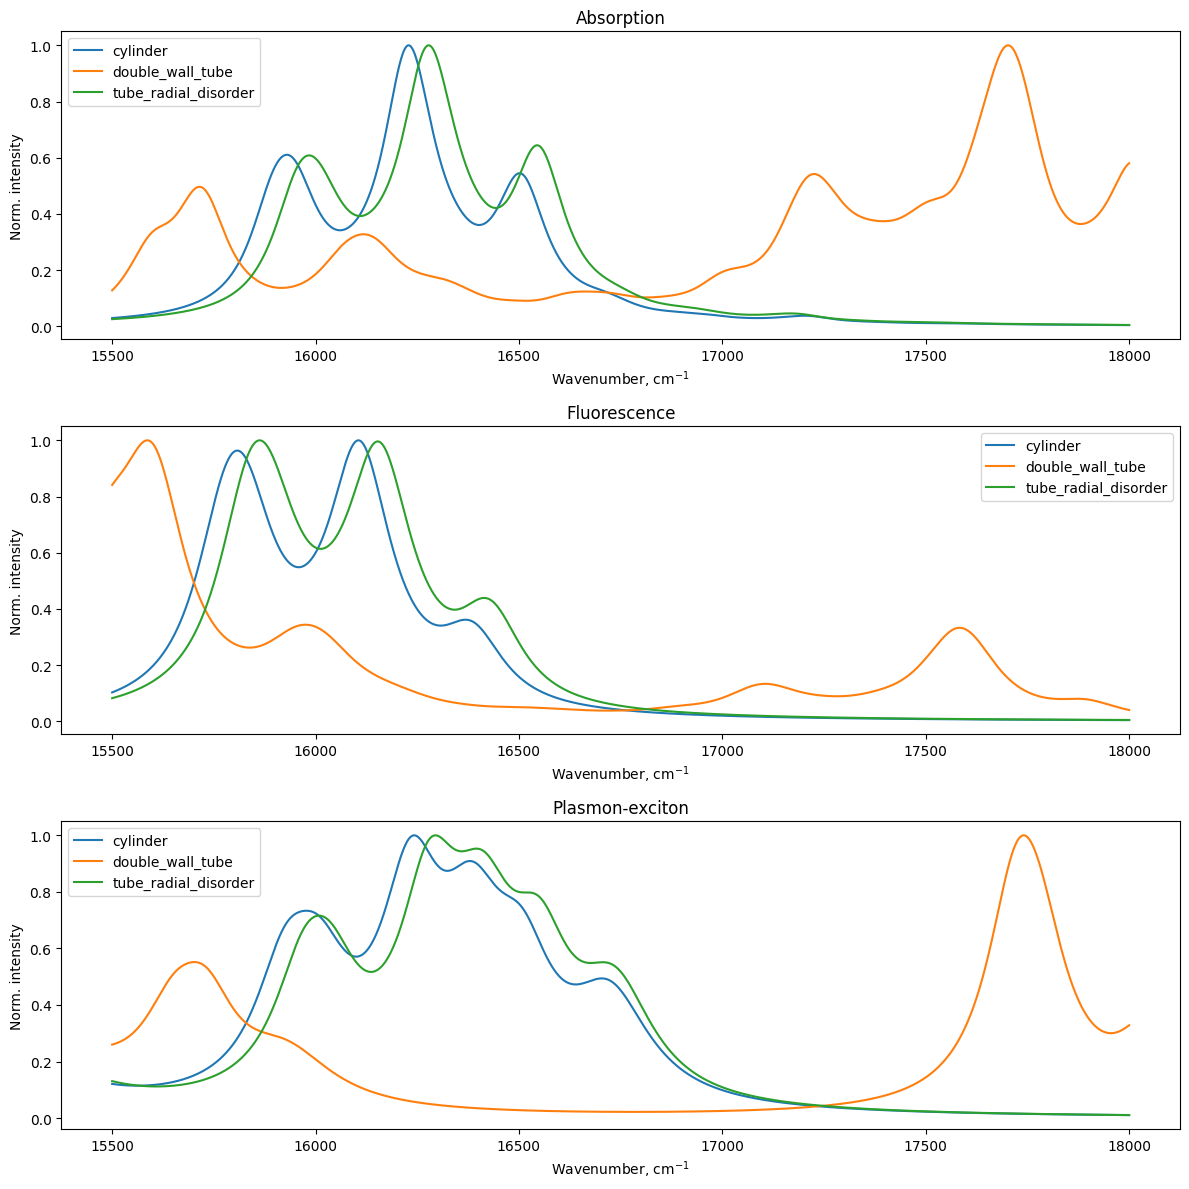

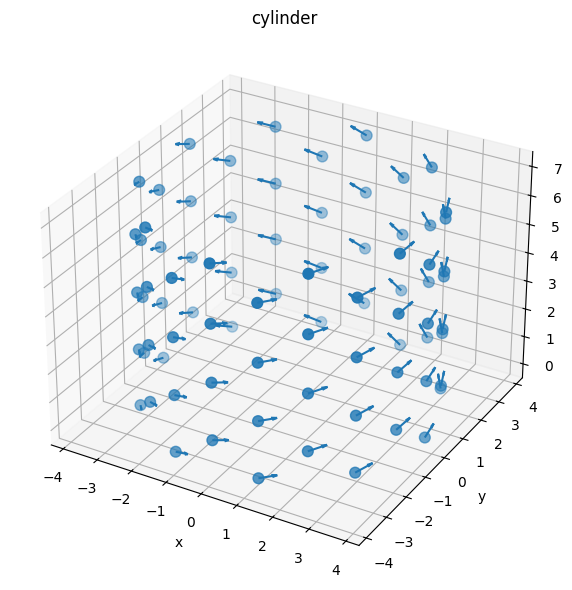

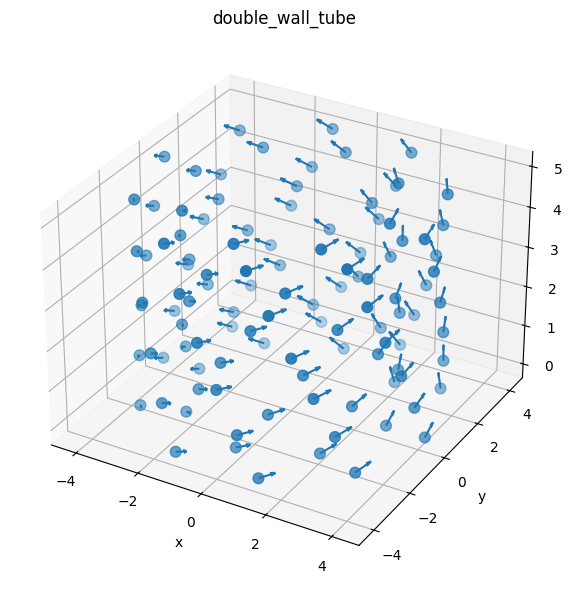

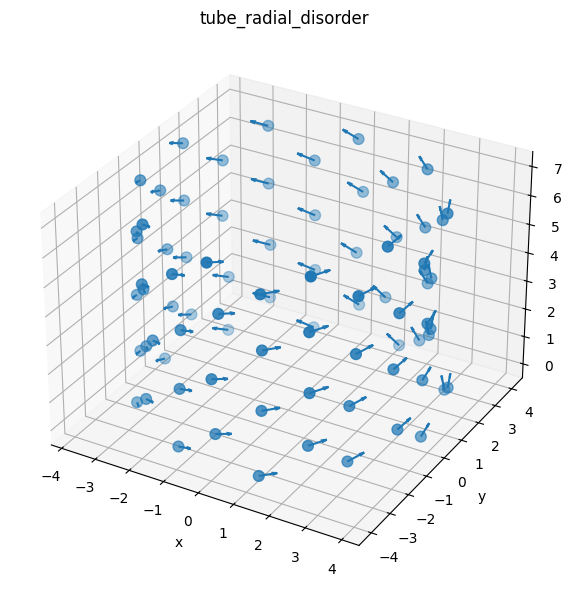

In [ ]:


if __name__ == "__main__":
    configs_demo = [
        {
            "name": "cylinder",
            "geometry_type": "cylinder",
            "geometry_params": {
                "n_rings": 8,
                "molecules_per_ring": 10,
                "radius": 3.8,
                "pitch": 1.0,
                "helical_twist_deg": 18.0,
                "dipole_tilt_deg": 22.0,
                "dipole_azimuthal": True
            }
        },
        {
            "name": "double_wall_tube",
            "geometry_type": "double_wall_tube",
            "geometry_params": {
                "n_rings": 6,
                "molecules_per_ring_inner": 8,
                "molecules_per_ring_outer": 10,
                "radius_inner": 3.0,
                "radius_outer": 4.2,
                "pitch": 1.0,
                "helical_twist_deg": 18.0,
                "wall_offset_deg": 10.0,
                "dipole_tilt_deg": 22.0,
                "dipole_azimuthal": True
            }
        },
        {
            "name": "tube_radial_disorder",
            "geometry_type": "tube_radial_disorder",
            "geometry_params": {
                "n_rings": 8,
                "molecules_per_ring": 10,
                "radius": 3.8,
                "radial_sigma": 0.20,
                "pitch": 1.0,
                "helical_twist_deg": 18.0,
                "dipole_tilt_deg": 22.0,
                "dipole_azimuthal": True,
                "seed": 11
            }
        }
    ]

    exciton_params = {
        "monomer_energy_cm": 17000.0,
        "J0": 950.0,
        "disorder_sigma_cm": 80.0
    }

    disorder_params = {
        "n_realizations": 30,
        "T": 300.0,
        "W0": 1.5,
        "spectral_cutoff_cm": 250.0,
        "gamma_abs_cm": 70.0,
        "gamma_em_cm": 90.0,
        "stokes_shift_cm": 120.0,
        "gamma_rad_base": 0.02,
        "gamma_nr": 0.003,
        "wmin": 15500.0,
        "wmax": 18000.0,
        "nw": 1800
    }

    results = simulate_configurations(
        configs=configs_demo,
        exciton_params=exciton_params,
        disorder_params=disorder_params,
        plasmon_shape="rod",
        plasmon_params={"aspect_ratio": 2.0}
    )

    # Plot summaries
    # plot_all_absorption(results)
    # plot_all_fluorescence(results)
    # plot_all_plexciton(results)
    plot_grouped_panels(results)
    # plot_per_configuration(results)

    # Optional: 3D geometry figures
    plot_geometries_from_configs(configs_demo)